В цьому ноутбуці наглядно демонструєтся робота бектест алгоритму на всій доступній історії аткиву

In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import numpy as np
import random
import yaml

from app import BacktestDCA
from ploter import ploter

/Users/aleksejkitajskij/Desktop/DCA/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# stocks

In [3]:
df_stocks = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_stocks

,BTC,ETH,SOL,XRP,DOGE,ADA,DOT,LINK,XLM,XMR
Date,,,,,,,,,,
2020-01-01,7200.174316,130.802002,NaN,0.192667,0.002033,0.033458,NaN,1.806640,0.045451,45.753544
2020-01-02,6985.470215,127.410179,NaN,0.188043,0.002009,0.032751,NaN,1.741144,0.044112,45.749470
2020-01-03,7344.884277,134.171707,NaN,0.193521,0.002145,0.034180,NaN,1.809708,0.045234,51.092037
2020-01-04,7410.656738,135.069366,NaN,0.194355,0.002241,0.034595,NaN,1.840133,0.046272,50.536694
2020-01-05,7411.317383,136.276779,NaN,0.195537,0.002419,0.034721,NaN,1.807787,0.045359,54.096893
...,...,...,...,...,...,...,...,...,...,...
2026-10-20,82941.000000,2446.730713,106.422340,1.334452,0.081809,0.223782,1.149771,12.320927,0.181960,600.929504
2026-10-21,84011.968750,2470.766113,106.793655,1.363619,0.081867,0.224979,1.141323,12.484719,0.183488,622.434082
2026-10-22,81311.890625,2386.189209,103.542320,1.307656,0.078676,0.212025,1.111869,11.943166,0.175209,600.638428


In [4]:
stock = 'DOT'
prices = df_stocks[stock].dropna()

In [5]:
strategy = {
    "buy_amount": 10,
}

01:02:54 - cmdstanpy - INFO - Chain [1] start processing
01:02:54 - cmdstanpy - INFO - Chain [1] done processing


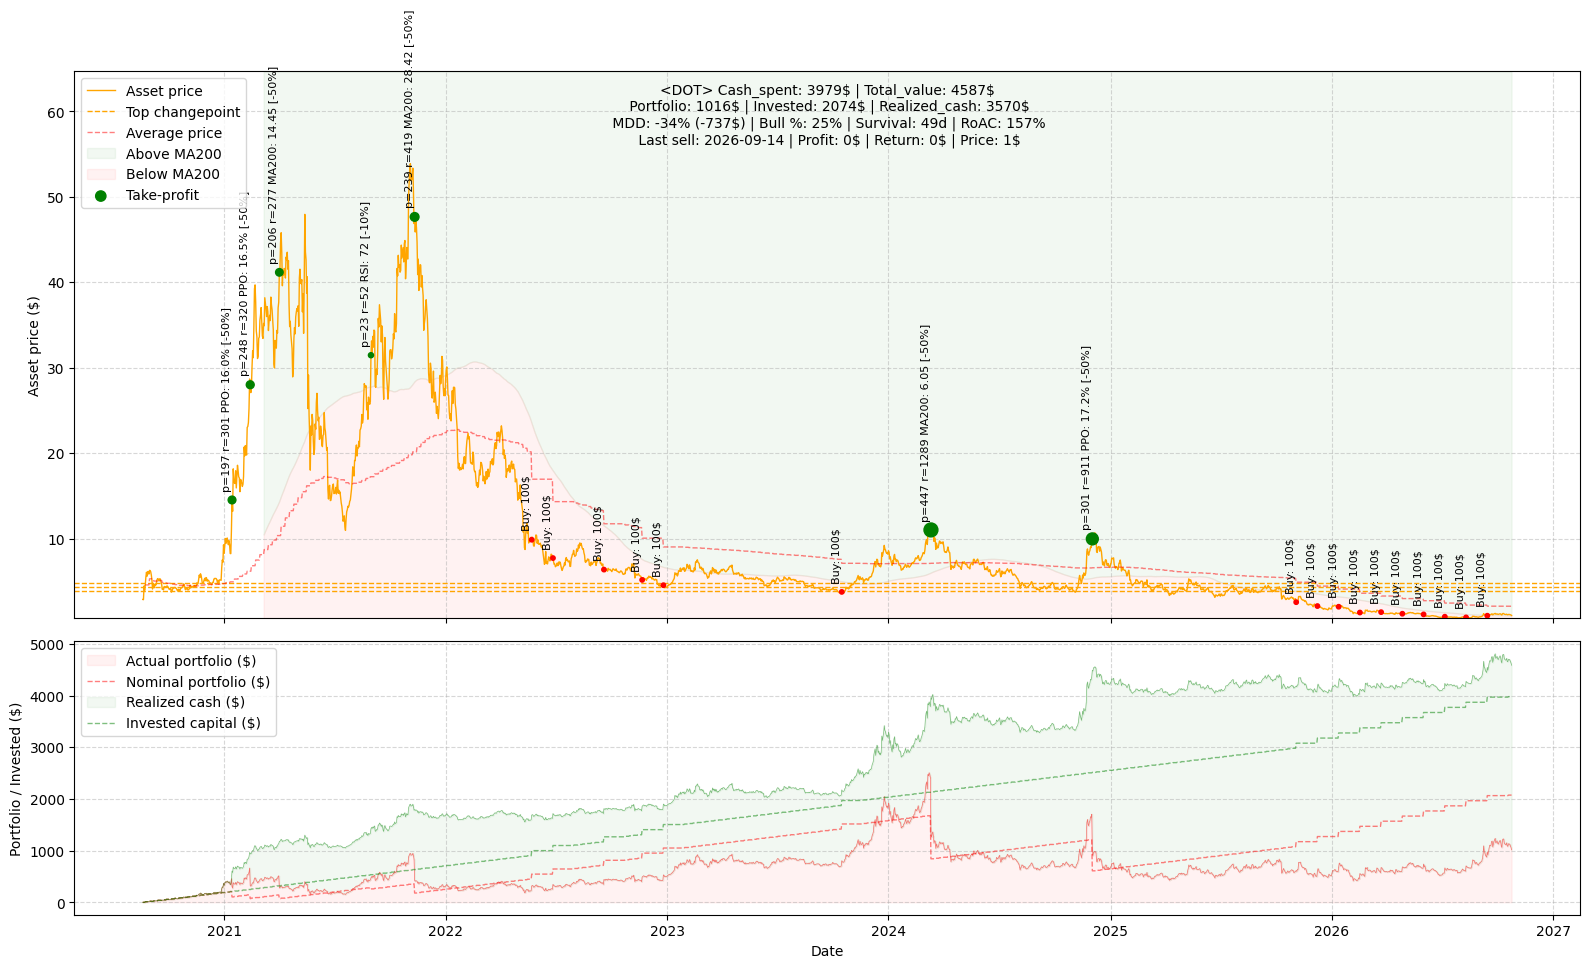

In [6]:
bt = BacktestDCA(
target=stock,
prices=prices,
strategy=strategy
)
result, metrics = bt.run()
ploter(metrics=metrics, history=result)

In [7]:
metrics

{'Target': 'DOT',
 'Cash_spent': 3979,
 'Realized_cash': 3570,
 'Portfolio': 1016,
 'Invested': 2074,
 'Total_value': 4587,
 'Bull_history': 25,
 'Avg_price': np.float64(2.1105014900001566),
 'Num_take_profits': 23,
 'MDD': -34,
 'MDD_usd': -737,
 'MA200_survival_days': 48.93103448275862,
 'RoAC': 157}

In [8]:
result

,Price,Portfolio_qty,Cost_basis,Cash_spent,Profit,Returns,Realized_cash,Trigger_msg,Portfolio,Average_price,Total_value
Date,,,,,,,,,,,
2020-08-20,2.900080,0.000000,0.000000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2020-08-21,2.875028,0.000000,0.000000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2020-08-22,4.484690,0.000000,0.000000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2020-08-23,3.967066,0.000000,0.000000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2020-08-24,4.602614,2.150952,9.900000,9.9,0.0,0.0,0.000000,,9.900000,4.602614,9.900000
...,...,...,...,...,...,...,...,...,...,...,...
2026-10-20,1.149771,982.853117,2074.312969,3979.8,0.0,0.0,3570.496791,,1130.055987,2.110501,4700.552778
2026-10-21,1.141323,982.853117,2074.312969,3979.8,0.0,0.0,3570.496791,,1121.752839,2.110501,4692.249630
2026-10-22,1.111869,982.853117,2074.312969,3979.8,0.0,0.0,3570.496791,,1092.803891,2.110501,4663.300682
